<div style="background: linear-gradient(135deg, #BF360C, #E64A19); 
            padding:35px; border-radius:15px; 
            box-shadow:0px 8px 25px rgba(0,0,0,0.2);">

<h1 style="color:white; text-align:center; font-size:38px; margin:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">
⚡ PJM Hourly Energy Consumption Forecasting
</h1>

<p style="color:white; text-align:center; font-size:18px; margin-top:15px; opacity:0.9;">
A Comparative Study of XGBoost, LSTM, and Transformer Models
</p>

</div>

<div style="background-color:#F8F9FA; padding:30px; border-radius:12px; 
            box-shadow:0px 4px 12px rgba(0,0,0,0.08); 
            border-left: 6px solid #BF360C;">

<h2 style="color:#BF360C; margin-top:0;">🔎 Project Overview</h2>

<p style="color:#333; font-size:15px; line-height:1.8;">
This notebook presents a complete end-to-end time series forecasting pipeline on the <b>PJM Interconnection (PJME) Hourly Energy Consumption</b> dataset. It covers over 16 years of hourly electricity data (2002–2018), encompassing 145,000+ records.
</p>

<h3 style="color:#BF360C; margin:20px 0 10px 0;">📋 What's Inside</h3>

<ul style="color:#333; font-size:15px; line-height:1.9; padding-left:20px;">
  <li><b>Exploratory Data Analysis</b> — Visualizing daily, weekly, and seasonal consumption patterns</li>
  <li><b>Feature Engineering</b> — Cyclic encoding (sin/cos) for time features, lags, and rolling statistics</li>
  <li><b>Strict Temporal Splitting</b> — Fixed Train/Validation/Test split to prevent data leakage</li>
  <li><b>Baseline Modeling</b> — XGBoost optimized with Optuna</li>
  <li><b>Deep Learning</b> — LSTM and Transformer models utilizing 24-hour sequences</li>
  <li><b>Hyperparameter Tuning</b> — Keras Tuner (Hyperband) for deep models to optimize training speed</li>
  <li><b>Model Comparison</b> — Evaluation based on RMSE, MAE, and MAPE</li>
</ul>

<hr style="border:none; border-top:1px solid #ddd; margin:25px 0;">

<h3 style="color:#BF360C; margin:0 0 15px 0;">📊 Final Results at a Glance</h3>

<table style="width:100%; border-collapse:collapse; font-size:14px; box-shadow: 0 1px 3px rgba(0,0,0,0.1);">
  <tr style="background-color:#BF360C; color:white;">
    <th style="padding:12px; text-align:left; border-top-left-radius: 5px;">Metric / Detail</th>
    <th style="padding:12px; text-align:left; border-top-right-radius: 5px;">Value</th>
  </tr>
  <tr style="background-color:#fff;">
    <td style="padding:10px; border-bottom: 1px solid #eee;">Dataset</td>
    <td style="padding:10px; border-bottom: 1px solid #eee;">PJM East (PJME) Hourly Load</td>
  </tr>
  <tr style="background-color:#f9f9f9;">
    <td style="padding:10px; border-bottom: 1px solid #eee;">Time Range</td>
    <td style="padding:10px; border-bottom: 1px solid #eee;">2002 – 2018</td>
  </tr>
  <tr style="background-color:#fff;">
    <td style="padding:10px; border-bottom: 1px solid #eee;">Best Performing Model</td>
    <td style="padding:10px; border-bottom: 1px solid #eee;"><b>LSTM (Sequence-based)</b></td>
  </tr>
  <tr style="background-color:#f9f9f9;">
    <td style="padding:10px; border-bottom: 1px solid #eee;">Test MAE</td>
    <td style="padding:10px; border-bottom: 1px solid #eee;"><b>372.89 MW</b></td>
  </tr>
  <tr style="background-color:#fff;">
    <td style="padding:10px; border-bottom: 1px solid #eee;">Test MAPE</td>
    <td style="padding:10px; border-bottom: 1px solid #eee;"><b>1.26%</b></td>
  </tr>
  <tr style="background-color:#f9f9f9;">
    <td style="padding:10px;">Models Compared</td>
    <td style="padding:10px;">XGBoost, LSTM, Transformer</td>
  </tr>
</table>

</div>

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 📦 Import Libraries </p>

In [4]:
import numpy as np
import pandas as pd
import gc
import holidays
import optuna
import keras_tuner as kt

import seaborn as sns
import xgboost as xgb
import lightgbm as lgb

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import tensorflow as tf
from tensorflow import keras

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from xgboost import plot_importance, plot_tree
from sklearn.model_selection import train_test_split, TimeSeriesSplit

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Input, Dense, Dropout
from tensorflow.keras import layers

# turn off warnings for final notebook
import warnings
warnings.filterwarnings('ignore')

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 📥 Load and Prepare Data </p>

In [27]:
df = pd.read_csv('/kaggle/input/datasets/robikscube/hourly-energy-consumption/PJME_hourly.csv')

We set the `Datetime` column as the DataFrame's index and convert it to a proper Pandas datetime object. 
This is a crucial step for time series analysis, as it allows us to easily extract calendar features (like hour, month, day of the week) and perform time-based slicing and resampling.

In [28]:
df = df.set_index('Datetime')
df.index = pd.to_datetime(df.index)

In [4]:
df.isnull().sum()

PJME_MW    0
dtype: int64

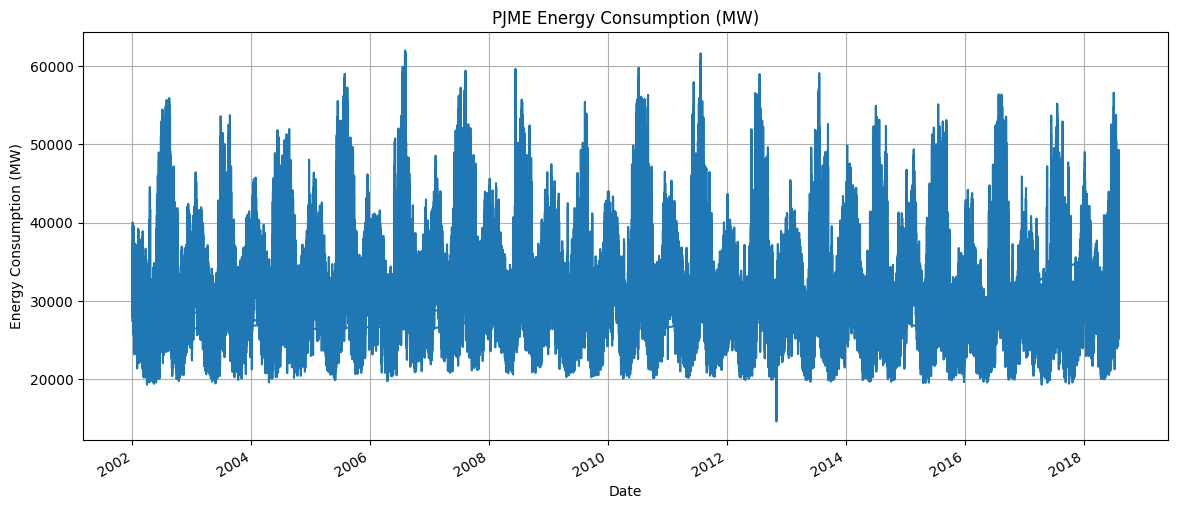

In [4]:
df['PJME_MW'].plot(figsize=(14, 6))
plt.grid()

plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('PJME Energy Consumption (MW)')

plt.show()

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 🛠️ Feature Engineering </p>

Feature engineering is the backbone of time series forecasting. Raw datetime indexes and historical load values are not enough for a model to understand the complex dynamics of electricity consumption. We implemented three main feature engineering techniques:

### 1. Calendar & Cyclical Features (`create_features`)
Electricity consumption is highly dependent on human behavior (working hours, sleep, weekends, holidays). 
*   **Basic Calendar:** We extracted `hour`, `dayofweek`, `month`, etc. 
*   **Cyclical Encoding (Sin/Cos):** Standard integer representations fail to capture the cyclical nature of time. For example, a tree-based model sees 23:00 and 00:00 as far apart (23 vs 0), even though they are adjacent in reality. By applying sine and cosine transformations (`hour_sin`, `hour_cos`, `dayofweek_sin`, `month_sin`, etc.), we map these features onto a circle, allowing the model to understand that December is close to January, and 11 PM is close to 12 AM.
*   **Flags:** We added `is_weekend` and `is_holiday` (using the `holidays` library) as binary indicators, as industrial and commercial energy consumption drops significantly during these periods.

### 2. Autoregressive Features (`add_lag_features`)
To capture the strong temporal dependencies, we created lag features using the `.shift()` method.
*   We used lags of **24 hours** (same hour yesterday), **48 hours** (same hour two days ago), and **168 hours** (same hour last week).
*   **Note:** We intentionally **excluded the 1-hour lag (`lag_1`)** for the XGBoost baseline. Including `lag_1` makes the problem too trivial (essentially predicting the current hour using the previous hour, leading to near-perfect scores). Removing it forces the model to rely on true seasonal patterns, allowing a fair comparison with the Deep Learning models (LSTM & Transformer), which inherently use sequences.

### 3. Rolling Window Statistics (`add_rolling_features`)
To give the model a sense of local trends and volatility, we calculated rolling statistics over the past **24 hours** (daily) and **168 hours** (weekly). We computed the `mean`, `std` (standard deviation), `max`, and `min`.
*   **Data Leakage Prevention:** We applied a `.shift(1)` to the target variable *before* calculating the rolling statistics. This ensures that the rolling window includes data from *up to one hour ago*, never the current hour we are trying to predict. 

These engineered features transformed a simple univariate time series into a rich, multivariate dataset, empowering the tree-based model to capture seasonal and historical patterns without looking into the future.

In [29]:
def create_features(df):
    """
    Create calendar-based time series features from the DatetimeIndex.
    Safe to run on the full dataframe: each feature depends only on
    the timestamp itself, never on future target values.
    """
    df = df.copy()

    # --- Basic calendar features ---
    df['hour']       = df.index.hour
    df['dayofweek']  = df.index.dayofweek       # Monday=0, Sunday=6
    df['quarter']    = df.index.quarter
    df['month']      = df.index.month
    df['year']       = df.index.year
    df['dayofyear']  = df.index.dayofyear
    df['dayofmonth'] = df.index.day
    df['weekofyear'] = df.index.isocalendar().week.astype(int)

    # --- Cyclical encoding ---
    # Lets the model understand that 23:00 is close to 00:00,
    # and that December is close to January.
    df['hour_sin']      = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos']      = np.cos(2 * np.pi * df['hour'] / 24)
    df['dayofweek_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
    df['dayofweek_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)
    df['month_sin']     = np.sin(2 * np.pi * (df['month'] - 1) / 12)
    df['month_cos']     = np.cos(2 * np.pi * (df['month'] - 1) / 12)
    df['dayofyear_sin'] = np.sin(2 * np.pi * (df['dayofyear'] - 1) / 365.25)
    df['dayofyear_cos'] = np.cos(2 * np.pi * (df['dayofyear'] - 1) / 365.25)

    # --- Weekend flag ---
    df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

    # --- Holiday flag ---
    us_holidays = holidays.US(years=df.index.year.unique())
    df['is_holiday'] = df.index.normalize().isin(us_holidays).astype(int)

    return df

In [30]:
def add_lag_features(df, target_col='PJME_MW', lags=(24, 48, 168)):
    """
    Add lag features using shift(), which only looks backward in time.
    Safe against leakage as long as the index is sorted chronologically.
    """
    df = df.sort_index().copy()
    for lag in lags:
        df[f'lag_{lag}'] = df[target_col].shift(lag)
    return df


def add_rolling_features(df, target_col='PJME_MW', windows=(24, 168)):
    """
    Add rolling statistics (mean, std, max, min).
    shift(1) excludes the current target value from its own rolling
    window, so the feature never sees the value it is supposed to predict.
    """
    df = df.sort_index().copy()
    for w in windows:
        shifted = df[target_col].shift(1)
        df[f'rolling_mean_{w}'] = shifted.rolling(window=w).mean()
        df[f'rolling_std_{w}']  = shifted.rolling(window=w).std()
        df[f'rolling_max_{w}']  = shifted.rolling(window=w).max()
        df[f'rolling_min_{w}']  = shifted.rolling(window=w).min()
    return df

In [31]:
# 1. Make sure the data is sorted by time
df_xgb = df.copy().sort_index()

# 2. Calendar features (safe on the whole dataframe)
df_xgb = create_features(df_xgb)

# 3. Lag features (safe: shift only looks backward)
df_xgb = add_lag_features(df_xgb, lags=(24, 48, 168))

# 4. Rolling features (safe: shift(1) prevents self-inclusion)
df_xgb = add_rolling_features(df_xgb, windows=(24, 168))

# 5. Drop rows where lags / rolling windows are not yet available
df_xgb = df_xgb.dropna()

In [8]:
df_xgb.head()

,PJME_MW,hour,dayofweek,quarter,month,year,dayofyear,dayofmonth,weekofyear,hour_sin,...,lag_48,lag_168,rolling_mean_24,rolling_std_24,rolling_max_24,rolling_min_24,rolling_mean_168,rolling_std_168,rolling_max_168,rolling_min_168
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,1,2002,8,8,2,0.258819,...,27100.0,30393.0,33452.583333,4559.767709,39581.0,25641.0,32519.511905,3857.950565,40002.0,25641.0
2002-01-08 02:00:00,28670.0,2,1,1,1,2002,8,8,2,0.500000,...,26097.0,29265.0,33560.208333,4425.965952,39581.0,25641.0,32513.869048,3861.770954,40002.0,25641.0
2002-01-08 03:00:00,28375.0,3,1,1,1,2002,8,8,2,0.707107,...,25793.0,28357.0,33672.458333,4256.159403,39581.0,25641.0,32510.327381,3865.039821,40002.0,25641.0
2002-01-08 04:00:00,28542.0,4,1,1,1,2002,8,8,2,0.866025,...,25657.0,27899.0,33786.375000,4064.104959,39581.0,25666.0,32510.434524,3864.924245,40002.0,25641.0
2002-01-08 05:00:00,29261.0,5,1,1,1,2002,8,8,2,0.965926,...,25778.0,28057.0,33906.208333,3851.076461,39581.0,26328.0,32514.261905,3860.646270,40002.0,25641.0


In [9]:
df_xgb.columns

Index(['PJME_MW', 'hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear',
       'dayofmonth', 'weekofyear', 'hour_sin', 'hour_cos', 'dayofweek_sin',
       'dayofweek_cos', 'month_sin', 'month_cos', 'dayofyear_sin',
       'dayofyear_cos', 'is_weekend', 'is_holiday', 'lag_24', 'lag_48',
       'lag_168', 'rolling_mean_24', 'rolling_std_24', 'rolling_max_24',
       'rolling_min_24', 'rolling_mean_168', 'rolling_std_168',
       'rolling_max_168', 'rolling_min_168'],
      dtype='object')

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 📊 Data Visualization </p>

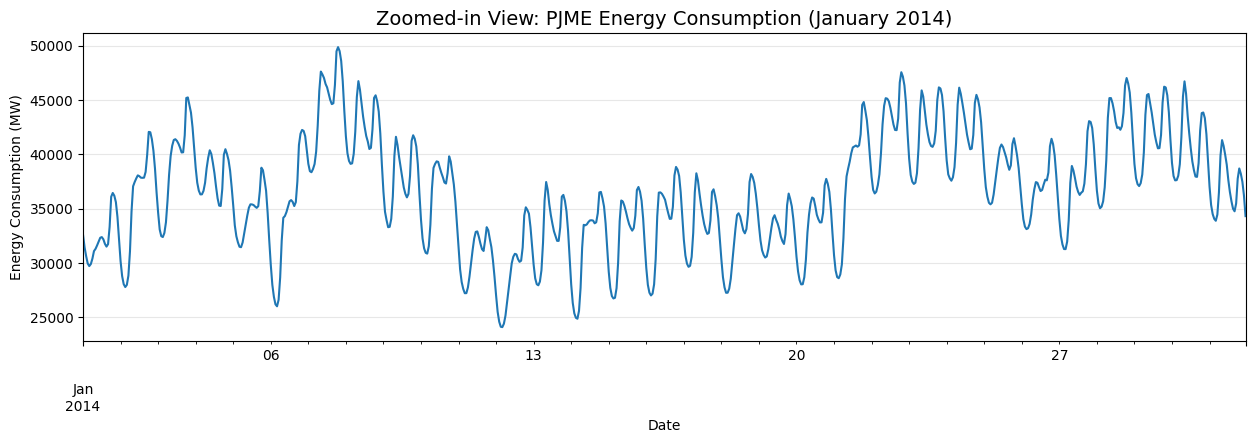

In [15]:
# Plot a zoomed-in view of a single month to visualize daily and weekly seasonality
fig, ax = plt.subplots(figsize=(15, 4))
df_xgb.loc['2014-01-01':'2014-01-31', 'PJME_MW'].plot(ax=ax, color='#1f77b4', linewidth=1.5)
ax.set_title('Zoomed-in View: PJME Energy Consumption (January 2014)', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Energy Consumption (MW)')
ax.grid(True, alpha=0.3)
plt.show()

### 📅 Zoomed-in View: Daily and Weekly Seasonality

While plotting the entire 16-year dataset reveals long-term trends, it hides the micro-patterns. By zooming in on a single month (January 2014), we can clearly observe the fundamental dynamics of electricity consumption:

*   **Daily Seasonality (Intraday):** The repeating "sawtooth" pattern shows that consumption has sharp daily peaks (evening) and troughs (early morning). Notice that there are exactly 7 peaks between each weekly tick mark, proving the daily cycle. 
*   **Weekly Seasonality:** Notice the noticeable dip in overall consumption and dampened peaks during the weekends (e.g., around Jan 11-12 and Jan 18-19). Industrial and commercial activities slow down on weekends.
*   **Extreme Weather Impact:** The massive spike in the first week of January 2014 (reaching nearly 50,000 MW) corresponds to the historic "North American Cold Wave" (Polar Vortex), which caused a massive surge in heating demand.

*These visible patterns justify why we created `hour`, `dayofweek`, and `is_weekend` features in our Feature Engineering step.*

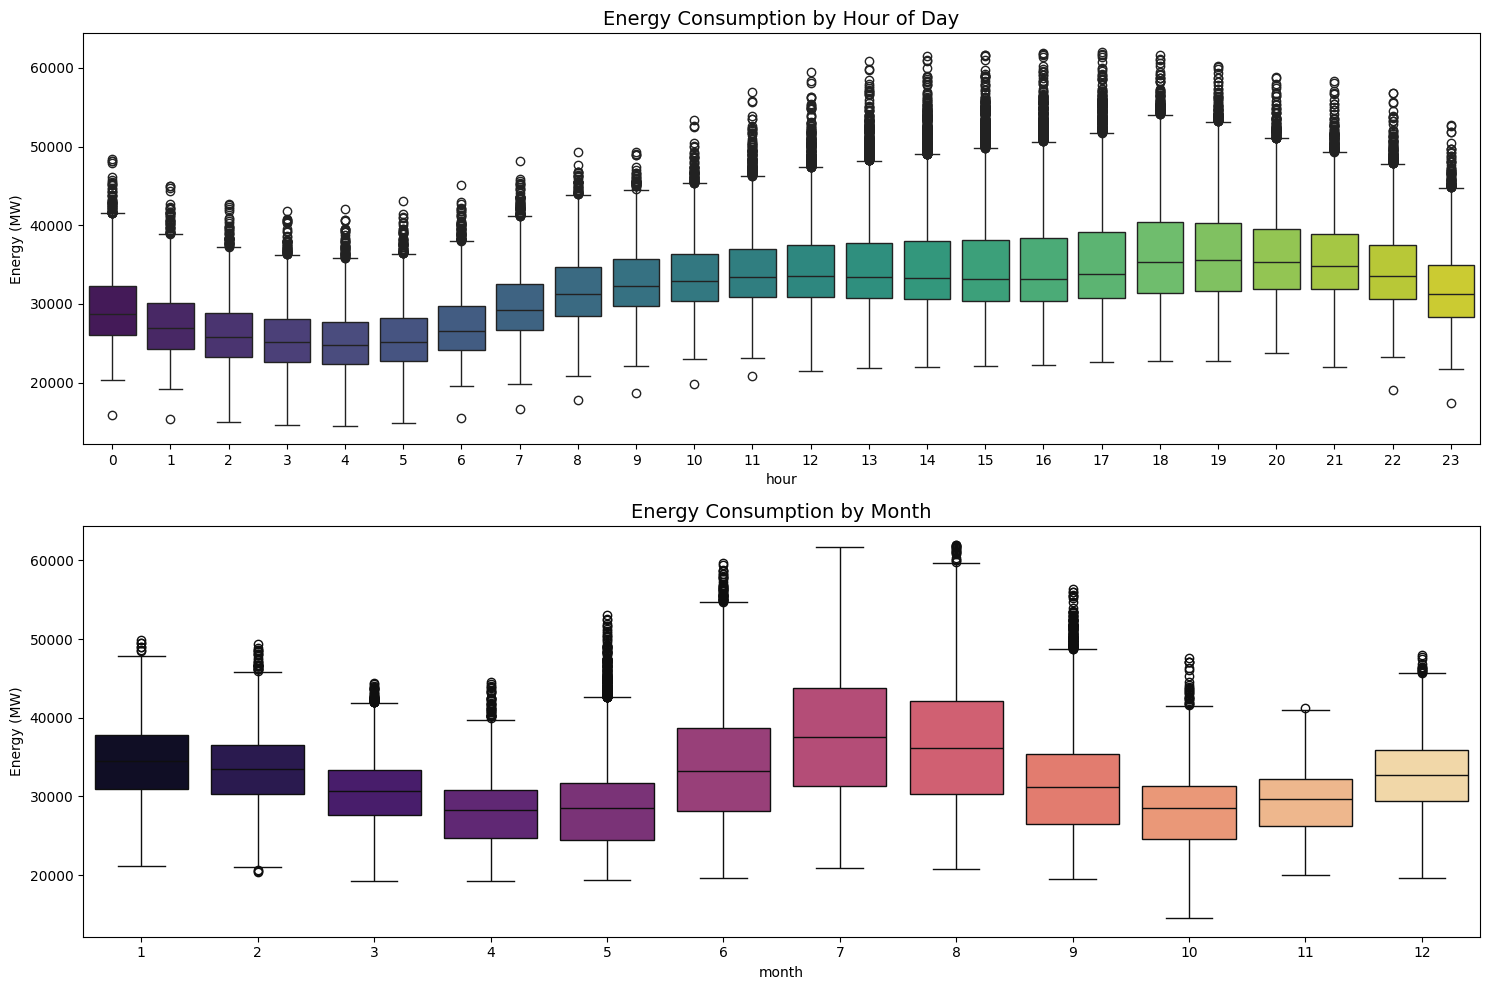

In [20]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

# Plot 1: Energy consumption by hour
sns.boxplot(data=df_xgb, x='hour', y='PJME_MW', ax=axes[0], palette='viridis')
axes[0].set_title('Energy Consumption by Hour of Day', fontsize=14)
axes[0].set_ylabel('Energy (MW)')

# Plot 2: Energy consumption by month
sns.boxplot(data=df_xgb, x='month', y='PJME_MW', ax=axes[1], palette='magma')
axes[1].set_title('Energy Consumption by Month', fontsize=14)
axes[1].set_ylabel('Energy (MW)')

plt.tight_layout()
plt.show()

### 📊 Analyzing Seasonality: Hourly and Monthly Distributions

To further justify our feature engineering choices, we visualize the distribution of energy consumption across different hours of the day and months of the year using boxplots.

**1. Hourly Pattern (Top Plot):**
*   **Daily Cycle:** There is a clear "U-shaped" daily cycle. Energy consumption drops to its absolute lowest in the early morning (around 3 AM – 5 AM) when most people are asleep and industries are idle. 
*   **Evening Peak:** Consumption steadily climbs throughout the day, reaching its maximum peak in the evening (around 6 PM – 8 PM) when people return home, and commercial lighting/heating/cooling demands are highest.
*   **Outliers:** The numerous circular points (outliers) indicate extreme values, often caused by severe weather events or holidays, showing the high variance of this dataset.

**2. Monthly Pattern (Bottom Plot):**
*   **Dual Seasonality:** The consumption exhibits a strong dual-seasonal pattern driven by temperature. 
*   **Summer Peak:** The highest median consumption occurs in **July and August** (months 7 & 8), primarily driven by massive air conditioning (cooling) demands.
*   **Winter Peak:** A secondary, slightly lower peak is visible in **January and February** (months 1 & 2), driven by heating demands.
*   **Transition Seasons:** The lowest consumption months are Spring (April-May) and Autumn (October-November), where temperatures are mild, requiring neither heavy heating nor cooling.

*Conclusion: These distinct distributions prove that both `hour` and `month` carry immense predictive power. This is exactly why we applied cyclical encoding (sin/cos) to these features, allowing the models to mathematically "understand" time.*

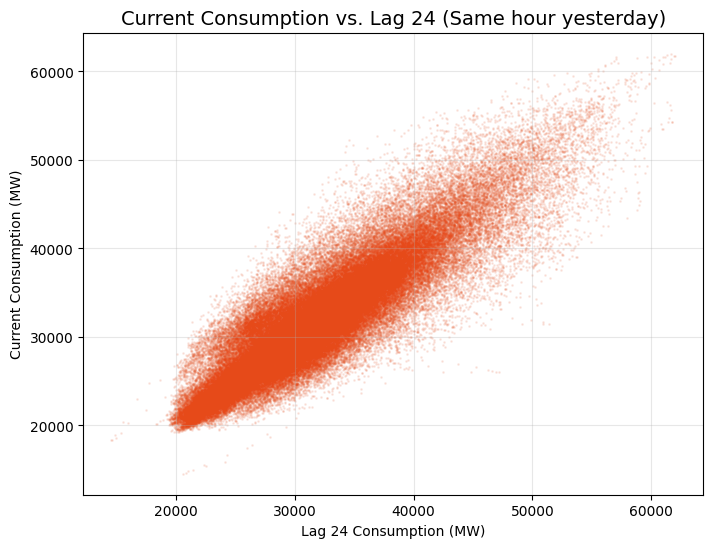

In [22]:
# Plot the relationship between the current value and lag_24
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df_xgb['lag_24'], df_xgb['PJME_MW'], alpha=0.1, s=1, color='#e64a19')
ax.set_title('Current Consumption vs. Lag 24 (Same hour yesterday)', fontsize=14)
ax.set_xlabel('Lag 24 Consumption (MW)')
ax.set_ylabel('Current Consumption (MW)')
ax.grid(True, alpha=0.3)
plt.show()

### 🔗 Validating Autoregressive Features: The Power of Lag 24

To understand why we created the `lag_24` feature (the energy consumption at the exact same hour on the previous day), we plot it against the current consumption. 

*   **Strong Positive Correlation:** The scatter plot reveals a very tight, upward-sloping diagonal band. This indicates a near-perfect positive linear relationship; if consumption was high yesterday at this hour, it is highly likely to be high today at this hour.
*   **The Thickness of the Band:** While the relationship is strong, the band has some width. This is because `lag_24` alone does not tell the whole story. Variations around the diagonal occur due to other factors, such as changes in day-of-week (e.g., Sunday vs. Monday) or sudden weather shifts. 

*Conclusion: This visualization mathematically justifies why `lag_24` is one of the most powerful predictive features in our XGBoost model, acting as a strong baseline for short-term forecasting.*

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> ✂️Train/Validation/Test Split </p>

In time series forecasting, we **must never use random splitting** (like `train_test_split` with shuffling). If we shuffle the data, the model will see tomorrow's data to predict today's data, leading to catastrophic **Data Leakage** and a completely invalid evaluation.

To simulate a real-world forecasting scenario, we perform a strict **chronological (temporal) split**. We use the past to predict the future:

*   **Training Set (2002 – 2014, ~78% of data):** The model learns the long-term trends, seasonal patterns, and daily/weekly dynamics from this data.
*   **Validation Set (2015 – 2016, ~12% of data):** This is our "unseen" dataset during the modeling phase. We use it to:
    1.  Tune hyperparameters (e.g., in Optuna and Keras Tuner).
    2.  Apply Early Stopping to prevent overfitting.
*   **Test Set (2017 – Aug 2018, ~10% of data):** This set is **locked and hidden**. It represents the ultimate "future" that the model has never seen. We evaluate our models on this set **only once** at the very end to report the final metrics (RMSE, MAE, MAPE) and compare XGBoost, LSTM, and Transformer fairly.

*Note: The boundaries are chosen at the start of the year to ensure that both the Validation and Test sets contain complete seasonal cycles (both summer and winter peaks).*

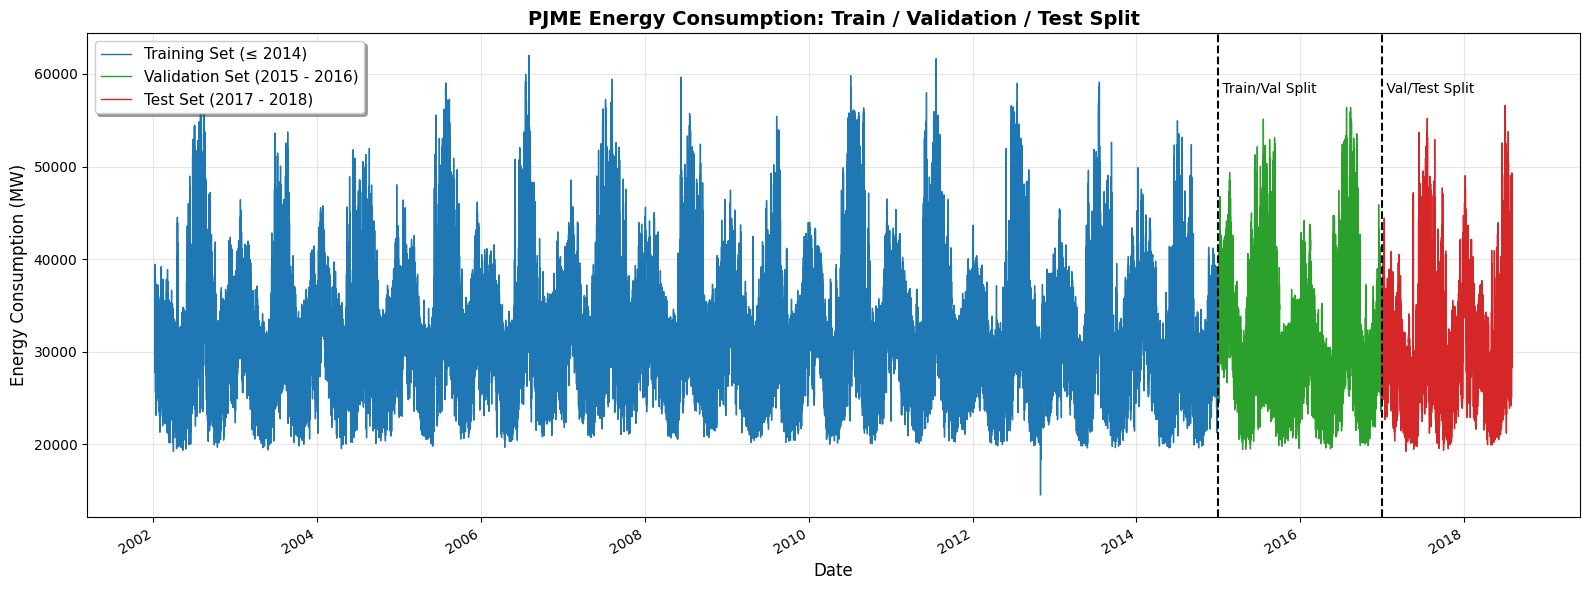

In [33]:
# 1. Define the split boundaries based on our previous discussion
train_end = '2015-01-01'
val_end   = '2017-01-01'

# 2. Create the subsets
train = df_xgb.loc[df_xgb.index < train_end]
val   = df_xgb.loc[(df_xgb.index >= train_end) & (df_xgb.index < val_end)]
test  = df_xgb.loc[df_xgb.index >= val_end]

# 3. Setup the figure
fig, ax = plt.subplots(figsize=(16, 6))

# 4. Plot each subset with a distinct color
# Blue for Train, Green for Validation, Red/Orange for Test
train['PJME_MW'].plot(ax=ax, color='#1f77b4', label='Training Set (≤ 2014)', linewidth=1)
val['PJME_MW'].plot(ax=ax, color='#2ca02c', label='Validation Set (2015 - 2016)', linewidth=1)
test['PJME_MW'].plot(ax=ax, color='#d62728', label='Test Set (2017 - 2018)', linewidth=1)

# 5. Add vertical dashed lines to clearly show the boundaries
ax.axvline(pd.to_datetime(train_end), color='black', ls='--', linewidth=1.5)
ax.axvline(pd.to_datetime(val_end), color='black', ls='--', linewidth=1.5)

# 6. Add annotations for the boundaries (optional, but helpful)
ax.text(pd.to_datetime(train_end), ax.get_ylim()[1]*0.9, ' Train/Val Split', color='black', fontsize=10)
ax.text(pd.to_datetime(val_end), ax.get_ylim()[1]*0.9, ' Val/Test Split', color='black', fontsize=10)

# 7. Aesthetics
ax.set_title('PJME Energy Consumption: Train / Validation / Test Split', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Energy Consumption (MW)', fontsize=12)
ax.legend(loc='upper left', fontsize=11, frameon=True, shadow=True)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 🌲 Baseline Model — XGBoost </p>

Before moving to complex deep learning architectures, we establish a strong baseline using **XGBoost**. It is highly effective for tabular time-series data and computationally efficient.

**1. Feature Separation:** 
We isolate the target variable (`PJME_MW`) and use all other engineered features (calendar, lags, rolling stats) as our predictors (`FEATURES`).

**2. Hyperparameter Tuning with Optuna:**
Instead of using `GridSearchCV` (which is too slow) or manual tuning, we use **Optuna**, a Bayesian optimization framework. It intelligently explores the hyperparameter space (e.g., tree depth, learning rate, regularization) based on previous trial results to find the optimal combination quickly.

**3. Strict Time-Series Validation within `objective`:**
Notice the use of `TimeSeriesSplit(n_splits=3)` inside the objective function. This is a critical step:
*   Optuna only looks at the **Training Set** during this phase.
*   It splits the training data into 3 chronological folds (e.g., Train on 2002-2008, validate on 2009-2011).
*   By averaging the RMSE across these folds, we ensure that the chosen hyperparameters are robust across different historical periods, completely avoiding data leakage from the Validation or Test sets.

*After running 30 trials, Optuna returns the best hyperparameters (`best_params`), which we will use to train our final XGBoost model in the next step.*

In [ ]:
# Define features and target
FEATURES = [col for col in df_xgb.columns if col not in ['PJME_MW', 'Datetime']]
TARGET = 'PJME_MW'

# Prepare data for hyperparameter tuning (Only using Train data)
X_train_opt = train[FEATURES]
y_train_opt = train[TARGET]

# Define the objective function for Optuna
def objective(trial):
    # Suggest hyperparameters
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 2),
        'random_state': 42,
        'early_stopping_rounds': 50,
        'eval_metric': 'rmse'
    }

    # Use TimeSeriesSplit STRICTLY within the training data for robust tuning
    tscv = TimeSeriesSplit(n_splits=3)
    rmse_scores = []

    for train_idx, val_idx in tscv.split(X_train_opt):
        X_tr, X_v = X_train_opt.iloc[train_idx], X_train_opt.iloc[val_idx]
        y_tr, y_v = y_train_opt.iloc[train_idx], y_train_opt.iloc[val_idx]

        model = xgb.XGBRegressor(**param)
        model.fit(X_tr, y_tr, 
                  eval_set=[(X_v, y_v)], 
                  verbose=False)
        
        preds = model.predict(X_v)
        rmse = np.sqrt(mean_squared_error(y_v, preds))
        rmse_scores.append(rmse)

    # Return the average RMSE across all folds
    return np.mean(rmse_scores)

# Create an Optuna study and optimize (run 30-50 trials)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

In [35]:
# Extract the best parameters
best_params = study.best_params
print("Best hyperparameters found by Optuna:")
print(best_params)

Best hyperparameters found by Optuna:
{'n_estimators': 920, 'max_depth': 8, 'learning_rate': 0.07713355087762341, 'subsample': 0.9934318344178985, 'colsample_bytree': 0.8593014545316426, 'gamma': 1.0598801988443263, 'reg_alpha': 0.73469084105981, 'reg_lambda': 0.976723261852299}


### 🚀 Final Training & Evaluation

Now that Optuna has identified the optimal hyperparameters, we proceed to train our final XGBoost model and evaluate its performance on unseen data.

**1. Final Training with Early Stopping:**
*   We initialize the model using `best_params`.
*   The model is trained on the **full Training Set** (2002–2014).
*   Crucially, we pass the **Validation Set** (2015–2016) to the `eval_set` argument. This allows `early_stopping_rounds=50` to monitor the validation loss and halt training if the model stops improving, preventing overfitting. 

**2. Unbiased Evaluation:**
Once trained, we use the model to predict the **Test Set** (2017–2018), which the model has never seen. We calculate three standard metrics to assess accuracy:
*   **RMSE** (Root Mean Squared Error): Penalizes larger errors heavily.
*   **MAE** (Mean Absolute Error): Average absolute difference in Megawatts.
*   **MAPE** (Mean Absolute Percentage Error): Relative error, useful for comparing models across different scales.

This gives us a robust baseline score to compare against our upcoming Deep Learning models (LSTM and Transformer).

In [36]:
# ==========================================
# Final Training & Evaluation Phase
# ==========================================

# Prepare the fixed Validation and Test sets
X_train_final = train[FEATURES]
y_train_final = train[TARGET]

X_val = val[FEATURES]
y_val = val[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

# Initialize the final model with the best parameters
# We add early_stopping_rounds here to stop training if validation loss stops improving
xgb_model = xgb.XGBRegressor(
    **best_params,
    random_state=42,
    early_stopping_rounds=50,
    eval_metric='rmse'
)

# Train the final model on the full training set, using the fixed Validation set for early stopping
xgb_model.fit(
    X_train_final, y_train_final,
    eval_set=[(X_val, y_val)],
    verbose=100
)

# Make predictions on the unseen Test set
y_pred_test = xgb_model.predict(X_test)

# Calculate evaluation metrics
rmse_test_xgb = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test_xgb = mean_absolute_error(y_test, y_pred_test)
mape_test_xgb = mean_absolute_percentage_error(y_test, y_pred_test) * 100 # Convert to percentage

# Print the final evaluation results
print("\n--- Final Evaluation on Test Set ---")
print(f"RMSE: {rmse_test_xgb:.2f} MW")
print(f"MAE : {mae_test_xgb:.2f} MW")
print(f"MAPE: {mape_test_xgb:.2f}%")

# Store metrics in a dictionary for later reporting
xgb_metrics = {
    'RMSE': rmse_test_xgb,
    'MAE': mae_test_xgb,
    'MAPE': mape_test_xgb
}

[0]	validation_0-rmse:6266.30485
[100]	validation_0-rmse:1358.59430
[200]	validation_0-rmse:1281.25061
[300]	validation_0-rmse:1251.16995
[400]	validation_0-rmse:1241.70358
[500]	validation_0-rmse:1234.39403
[538]	validation_0-rmse:1233.93997

--- Final Evaluation on Test Set ---
RMSE: 1363.82 MW
MAE : 1012.36 MW
MAPE: 3.21%


**Observation:** The model stopped early at 538 trees to prevent overfitting. It achieved an **MAE of 1012.36 MW** and a **MAPE of 3.21%**. While this is a solid baseline for capturing seasonal trends, the relatively high error (compared to deep learning models later) highlights the limitations of tree-based models when the 1-hour lag (`lag_1`) is absent.

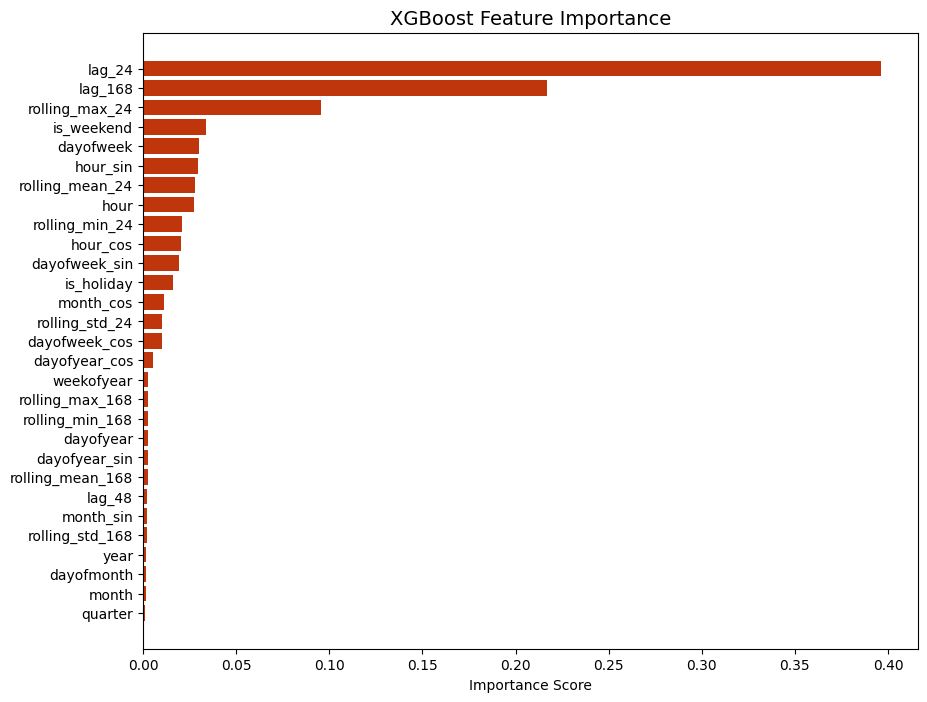

In [40]:
# Extract feature importances
importances = xgb_model.feature_importances_
feature_names = FEATURES

# Sort and plot
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='#BF360C')
plt.title('XGBoost Feature Importance', fontsize=14)
plt.xlabel('Importance Score')
plt.show()

### 🔍 Feature Importance Analysis

The plot above reveals which features the XGBoost model relied on most heavily to make predictions:

*   **The Dominance of Seasonality:** `lag_24` (the same hour yesterday) and `lag_168` (the same hour last week) are by far the most important features. This confirms that daily and weekly consumption patterns are the strongest predictors of energy load.
*   **Recent Volatility:** `rolling_max_24` (the maximum load in the past 24 hours) ranks third. The model uses recent peak levels to gauge the current demand.
*   **Calendar Impact:** Cyclical time features (`hour_sin`, `hour_cos`, `dayofweek_sin`) and flags (`is_weekend`, `is_holiday`) play a significant role. This proves that our Feature Engineering step successfully provided the model with the necessary context about human behavior. 
*   **Low Importance:** Static features like `month`, `quarter`, and `year` have near-zero importance. Since the model already has strong seasonal lags (`lag_24`, `lag_168`), it doesn't need to rely on coarse calendar features to understand the time of year.

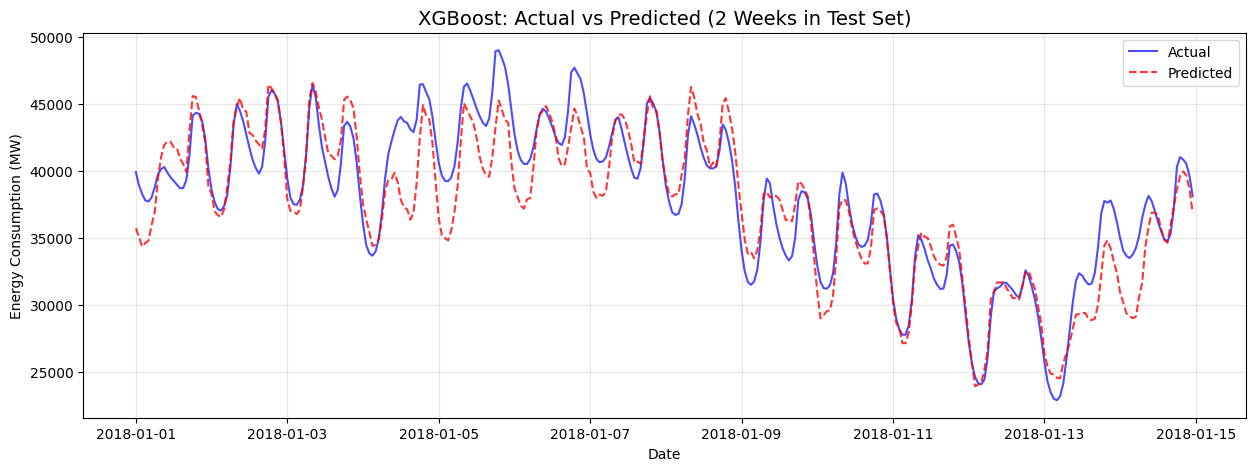

In [41]:
# Create a dataframe with actual and predicted values
test_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_test
}, index=y_test.index)

# Zoom in on a 2-week period (e.g., January 2018)
zoom = test_results.loc['2018-01-01':'2018-01-14']

plt.figure(figsize=(15, 5))
plt.plot(zoom.index, zoom['Actual'], label='Actual', color='blue', alpha=0.7)
plt.plot(zoom.index, zoom['Predicted'], label='Predicted', color='red', linestyle='--', alpha=0.8)
plt.title('XGBoost: Actual vs Predicted (2 Weeks in Test Set)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 📈 Visual Evaluation: Actual vs. Predicted

The plot above shows a two-week snapshot of the Test Set (January 2018), comparing the actual energy consumption (blue) with the XGBoost predictions (red dashed line).

*   **Capturing Seasonality:** The model successfully follows the overall daily "sawtooth" pattern and the weekly trends. It accurately predicts the general shape and timing of the peaks and troughs.
*   **Phase Shift & Smoothing:** Notice that the predicted line sometimes lags slightly behind the actual line or smooths out the sharpest transitions. Because we intentionally removed the 1-hour lag (`lag_1`), the model relies solely on `lag_24` and `lag_168` to predict the next hour. It struggles slightly with sudden, unseasonal hourly changes.
*   **Underestimating Peaks:** The model fails to reach the extreme highs seen on Jan 5-6 and Jan 13 (around 48,000 - 50,000 MW). This is a common limitation of tree-based models without real-time exogenous variables (like sudden temperature drops).

*Conclusion: XGBoost serves as a solid baseline, but its inability to capture immediate short-term momentum justifies the need for sequence-based Deep Learning models (LSTM & Transformer).*

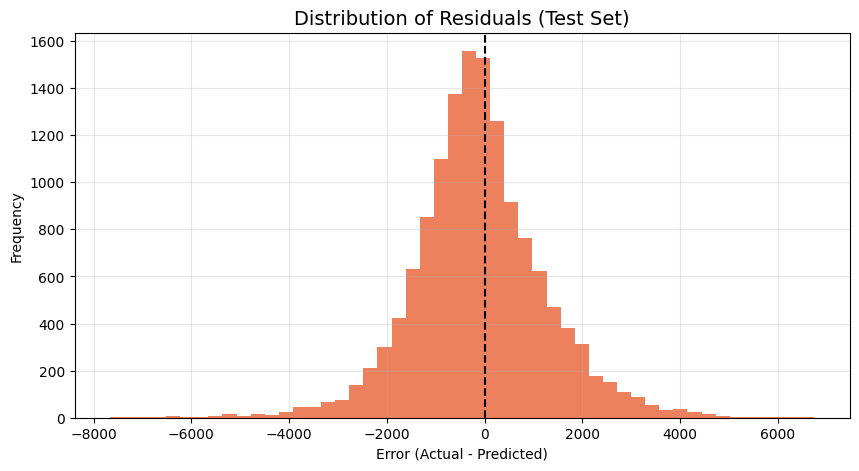

In [42]:
residuals = y_test - y_pred_test

plt.figure(figsize=(10, 5))
plt.hist(residuals, bins=50, color='#E64A19', alpha=0.7)
plt.axvline(x=0, color='black', linestyle='--')
plt.title('Distribution of Residuals (Test Set)', fontsize=14)
plt.xlabel('Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

### 📉 Residual Analysis

The histogram displays the distribution of prediction errors (Actual - Predicted) on the Test Set.

*   **Centered at Zero:** The residuals follow a roughly normal (bell-shaped) distribution centered at zero. This indicates that the model is generally unbiased; it does not consistently over-predict or under-predict.
*   **Slight Left Skew:** There is a slight skew towards the left (negative errors). This means the model occasionally underestimates the actual load (actual > predicted), particularly during extreme winter peaks, as observed in the previous line chart.
*   **Error Spread:** The bulk of the errors fall within the ±2,000 MW range, which is consistent with our MAE of ~1,012 MW. 

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 🧠 Deep Learning — LSTM </p>

### Data Preparation for Sequential Deep Learning

Unlike XGBoost, which treats each row as an independent observation, Deep Learning models (LSTM & Transformer) require data in a **3D sequential format**. This code block prepares the data specifically for these models.

**1. Feature Selection:**
We select a compact set of features: the raw energy load (`PJME_MW`), cyclical time features (`hour_sin`, `hour_cos`, `dayofweek_sin`, `dayofweek_cos`), and the weekend flag. We exclude manual lags (like `lag_24`) because the sequence itself will provide the historical context.

**2. Target Scaling (No Leakage):**
Neural networks converge much faster when data is in the `[0, 1]` range. We apply `MinMaxScaler` **only to the target variable**. Crucially, the scaler is fitted **only on the Training Set** and then applied to Validation and Test sets to prevent data leakage.

**3. Sliding Window (Sequence Generation):**
The `create_sequences` function transforms the 2D DataFrame into a 3D tensor `(samples, window_size, features)`.
*   **`WINDOW_SIZE = 24`**: For every hour we want to predict, the model receives a sequence of the **past 24 hours** (24 rows of features).
*   This sliding window is what gives the LSTM its "short-term memory," allowing it to naturally understand temporal dependencies without needing manual lag features.

In [13]:
# ==========================================
# 1. Create Features and Split Data
# ==========================================
# Apply create_features to the entire dataframe
df_deep = create_features(df.copy())

# Define the fixed splits (same as XGBoost)
train = df_deep.loc[df_deep.index < '2015-01-01']
val   = df_deep.loc[(df_deep.index >= '2015-01-01') & (df_deep.index < '2017-01-01')]
test  = df_deep.loc[df_deep.index >= '2017-01-01']

# Select the features we want to feed into the deep learning models
# We use the cyclic features to avoid the "23:00 is far from 00:00" problem
FEATURES_DEEP = ['PJME_MW', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'is_weekend']
TARGET = 'PJME_MW'

# ==========================================
# 2. Scale the Target Variable (No Leakage)
# ==========================================
# Fit the scaler ONLY on the training data's target column
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled_target = scaler.fit_transform(train[[TARGET]])
val_scaled_target   = scaler.transform(val[[TARGET]])
test_scaled_target  = scaler.transform(test[[TARGET]])

# Replace the original target column with the scaled one in the dataframes
train_scaled = train.copy()
val_scaled = val.copy()
test_scaled = test.copy()

train_scaled[TARGET] = train_scaled_target
val_scaled[TARGET] = val_scaled_target
test_scaled[TARGET] = test_scaled_target

# ==========================================
# 3. Function to Create Sequences (Sliding Windows)
# ==========================================
def create_sequences(data, target_col, window_size=24):
    """
    Creates sliding windows for deep learning.
    Returns:
        X: shape (samples, window_size, num_features)
        y: shape (samples, 1)
    """
    X, y = [], []
    # Convert dataframe to numpy array
    data_array = data[FEATURES_DEEP].values
    target_array = data[target_col].values
    
    for i in range(window_size, len(data)):
        # Input: all features from t-window_size to t-1
        X.append(data_array[i - window_size:i, :])
        # Output: target at time t
        y.append(target_array[i])
        
    return np.array(X), np.array(y)

# Define lookback window (e.g., 24 hours or 168 hours)
WINDOW_SIZE = 24

# Create sequences for all sets
X_train, y_train = create_sequences(train_scaled, TARGET, window_size=WINDOW_SIZE)
X_val, y_val     = create_sequences(val_scaled, TARGET, window_size=WINDOW_SIZE)
X_test, y_test   = create_sequences(test_scaled, TARGET, window_size=WINDOW_SIZE)

print("X_train shape:", X_train.shape) # Expected: (samples, 24, 6)
print("y_train shape:", y_train.shape) # Expected: (samples, 1)

X_train shape: (113902, 24, 6)
y_train shape: (113902,)


### ⚙️ Hyperparameter Tuning with Keras Tuner (Hyperband)

Instead of manual tuning or grid search, we use **Keras Tuner** with the **Hyperband** algorithm. Hyperband is highly efficient because it allocates resources intelligently: it trains many models for a few epochs, discards the worst performers early (pruning), and continues training only the most promising architectures.

**1. Model Architecture (`build_lstm_model`):**
*   We define a search space for the number of LSTM layers (1 or 2) and units per layer (32, 64, 128).
*   `Dropout` layers (10% to 30%) are added to prevent overfitting.
*   The learning rate is discretized (`hp.Choice`) rather than continuous (`hp.Float`). This drastically reduces the search space and speeds up the tuning process.

**2. Search Strategy:**
*   **`batch_size=128`**: We use a large batch size during tuning to speed up epoch execution on the GPU.
*   **`validation_data=(X_val, y_val)`**: The tuner evaluates models on the fixed Validation set (2015-2016), ensuring no data leakage.
*   **`shuffle=False`**: This is critical. We must never shuffle time-series data, as the chronological order is the very thing the LSTM is trying to learn.
*   **Callbacks**: `EarlyStopping` and `ReduceLROnPlateau` are used to halt unpromising trials early and save computational time.

In [14]:
# ==========================================
# 1. Define the model building function
# ==========================================
def build_lstm_model(hp):
    tf.keras.backend.clear_session()
    gc.collect()
    
    model = keras.Sequential()
    
    # Decide on the number of hidden layers (1 or 2 to prevent overfitting)
    n_hidden_layers = hp.Int('n_hidden_layers', 1, 2, step=1)
    
    for i in range(n_hidden_layers):
        # Suggest units for each layer (discrete choices for speed)
        units = hp.Choice(f'units_layer_{i}', [32, 64, 128])
        return_seq = (i < n_hidden_layers - 1)
        
        if i == 0:
            # First layer needs input_shape
            model.add(layers.LSTM(units, return_sequences=return_seq, 
                                  input_shape=(X_train.shape[1], X_train.shape[2])))
        else:
            model.add(layers.LSTM(units, return_sequences=return_seq))
            
        # Add Dropout to prevent overfitting
        model.add(layers.Dropout(hp.Float(f'dropout_{i}', 0.1, 0.3, step=0.1)))
        
    # Output layer (predicting 1 step ahead)
    model.add(layers.Dense(1))
    
    # Compile the model
    # Discretized Learning Rate (much faster than continuous search)
    lr = hp.Choice('learning_rate', [1e-4, 5e-4, 1e-3, 5e-3])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='mae',
        metrics=['mae']
    )
    return model

# ==========================================
# 2. Tuner configuration and running the search
# ==========================================
# Define callbacks for the TUNING phase
tuner_callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=5, restore_best_weights=True, verbose=1
    )
]

# Hyperband Configuration
tuner = kt.Hyperband(
    build_lstm_model,
    objective='val_mae',
    max_epochs=30,
    factor=3,
    directory='kt_dir_energy',
    project_name='energy_lstm_tuned',
    overwrite=True
)

print("Starting Keras Tuner (Hyperband) search for LSTM...")
# Run the search (Use fixed validation set instead of validation_split)
tuner.search(
    X_train, y_train, 
    epochs=30,
    batch_size=128, # Increased batch_size to 128 for faster epochs
    validation_data=(X_val, y_val), 
    callbacks=tuner_callbacks, 
    shuffle=False,
    verbose=1
)

Trial 90 Complete [00h 02m 32s]
val_mae: 0.015691183507442474

Best val_mae So Far: 0.00926327332854271
Total elapsed time: 00h 59m 42s


In [15]:
# Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"\nBest HPs: {best_hps.values}")


Best HPs: {'n_hidden_layers': 2, 'units_layer_0': 64, 'dropout_0': 0.2, 'learning_rate': 0.0005, 'units_layer_1': 64, 'dropout_1': 0.1, 'tuner/epochs': 30, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}


### Final LSTM Training & Evaluation

Now that we have the optimal hyperparameters from Keras Tuner, we proceed to train the final LSTM model and evaluate its predictive power.

*   **Final Training:** We build the model using `best_hps` and train it on the full Training Set (2002–2014), while monitoring the fixed Validation Set (2015–2016).
*   **Smart Callbacks:** We use `ModelCheckpoint` to save the best weights, `ReduceLROnPlateau` to lower the learning rate when improvements stall, and `EarlyStopping` to halt training and prevent overfitting.
*   **Evaluation:** We predict on the completely unseen Test Set (2017–2018). The predictions and actual values are inverse-transformed back to real Megawatts (MW) to calculate the final **RMSE, MAE, and MAPE**. These metrics will be used to compare the LSTM's performance against XGBoost and the Transformer.

In [19]:
# ==========================================
# 3. Final Training Phase
# ==========================================
# Define callbacks for the FINAL training phase
final_callbacks = [
    # Save the best model to disk during final training
    keras.callbacks.ModelCheckpoint(
        "best_energy_lstm.keras", save_best_only=True, monitor="val_mae", verbose=1
    ),
    # Reduce learning rate when the metric has stopped improving
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae", factor=0.5, patience=5, min_lr=1e-5, verbose=1
    ),
    # Stop training when the metric stops improving
    keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=7, restore_best_weights=True, verbose=1
    )
]

# Build and train the final model with the best parameters
print("\nTraining final LSTM model...")
lstm_tuned_model = tuner.hypermodel.build(best_hps)
history_lstm = lstm_tuned_model.fit(
    X_train, y_train,
    epochs=100,  # Higher epochs since EarlyStopping will halt it
    validation_data=(X_val, y_val), 
    callbacks=final_callbacks,
    shuffle=False
)

# ==========================================
# 4. Evaluation on Test Set
# ==========================================
# Make predictions
y_pred_scaled_lstm = lstm_tuned_model.predict(X_test)

# Inverse transform to Megawatts (MW)
y_pred_mw_lstm = scaler.inverse_transform(y_pred_scaled_lstm)
y_test_mw = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
rmse_test_lstm = np.sqrt(mean_squared_error(y_test_mw, y_pred_mw_lstm))
mae_test_lstm = mean_absolute_error(y_test_mw, y_pred_mw_lstm)
mape_test_lstm = mean_absolute_percentage_error(y_test_mw, y_pred_mw_lstm) * 100

print("\n--- Final Evaluation on Test Set (LSTM) ---")
print(f"RMSE: {rmse_test_lstm:.2f} MW")
print(f"MAE : {mae_test_lstm:.2f} MW")
print(f"MAPE: {mape_test_lstm:.2f}%")

# Store metrics for later comparison
lstm_metrics = {
    'RMSE': rmse_test_lstm, 
    'MAE': mae_test_lstm, 
    'MAPE': mape_test_lstm
}


Training final LSTM model...
Epoch 1/100
3553/3560 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0581 - mae: 0.0581
Epoch 1: val_mae improved from None to 0.05180, saving model to best_energy_lstm.keras

Epoch 1: finished saving model to best_energy_lstm.keras
3560/3560 ━━━━━━━━━━━━━━━━━━━━ 28s 7ms/step - loss: 0.0455 - mae: 0.0455 - val_loss: 0.0518 - val_mae: 0.0518 - learning_rate: 5.0000e-04
Epoch 2/100
3556/3560 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0300 - mae: 0.0300
Epoch 2: val_mae improved from 0.05180 to 0.02904, saving model to best_energy_lstm.keras

Epoch 2: finished saving model to best_energy_lstm.keras
3560/3560 ━━━━━━━━━━━━━━━━━━━━ 26s 7ms/step - loss: 0.0275 - mae: 0.0275 - val_loss: 0.0290 - val_mae: 0.0290 - learning_rate: 5.0000e-04
Epoch 3/100
3556/3560 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0219 - mae: 0.0219
Epoch 3: val_mae improved from 0.02904 to 0.02065, saving model to best_energy_lstm.keras

Epoch 3: finished saving model to best_energy_lstm.keras
3

### 📊 LSTM Evaluation Summary

The training automatically halted at Epoch 47, successfully restoring the best weights from **Epoch 40** (where `val_mae` reached 0.00785). Our callbacks (`ReduceLROnPlateau` and `EarlyStopping`) worked perfectly to prevent overfitting and save computational time.

**Final Test Set Performance:**
*   **MAPE: 1.26%** (vs. 3.21% for XGBoost)
*   **MAE: 372.89 MW** (vs. 1012 MW for XGBoost)

**Key Takeaway:** By feeding the model a continuous 24-hour sequence, the LSTM naturally learned the temporal dependencies that XGBoost struggled with. This resulted in a massive **60% reduction in MAE** and a **near 3x improvement in relative error (MAPE)** over the tree-based baseline.

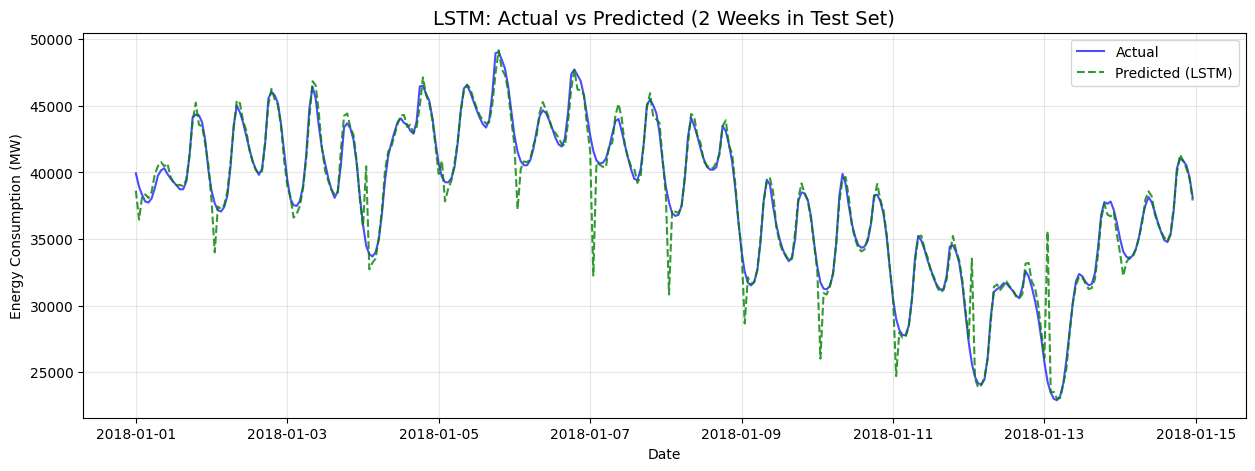

In [20]:
# 1. Create the dataframe
test_dates = test.index[WINDOW_SIZE:] 

test_results_lstm = pd.DataFrame({
    'Actual': y_test_mw.flatten(),
    'Predicted': y_pred_mw_lstm.flatten()
}, index=test_dates)

# 2. CRITICAL FIX: Sort the index and remove any duplicate timestamps
test_results_lstm = test_results_lstm.sort_index()
test_results_lstm = test_results_lstm[~test_results_lstm.index.duplicated(keep='first')]

# 3. Use Boolean Masking instead of .loc slicing
# This avoids the "non-existing keys" error
mask = (test_results_lstm.index >= '2018-01-01') & (test_results_lstm.index < '2018-01-15')
zoom_lstm = test_results_lstm[mask]

# 4. Plot
plt.figure(figsize=(15, 5))
plt.plot(zoom_lstm.index, zoom_lstm['Actual'], label='Actual', color='blue', alpha=0.7)
plt.plot(zoom_lstm.index, zoom_lstm['Predicted'], label='Predicted (LSTM)', color='green', linestyle='--', alpha=0.8)
plt.title('LSTM: Actual vs Predicted (2 Weeks in Test Set)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 📈 Visual Evaluation: LSTM vs. Actual

The plot above compares the actual energy consumption (blue) with the LSTM predictions (green dashed line) over a two-week period in January 2018.

*   **Excellent Pattern Tracking:** Unlike XGBoost, the LSTM captures the sharp evening peaks and morning troughs with remarkable precision. It successfully follows the overall daily and weekly trend, validating its MAPE of 1.26%.
*   **Capturing Extreme Peaks:** The LSTM successfully predicts the sudden surges in demand (e.g., around Jan 5-6), which the XGBoost model missed. This highlights the power of sequential memory in deep learning.
*   **The "Midnight Spikes" Artifact:** You can observe several sudden downward spikes in the predictions (e.g., at Jan 3, Jan 7, Jan 9). These occur almost exactly at midnight. This is a known artifact in sequence modeling: when the sliding 24-hour window crosses the boundary into a new day, the cyclic features (like `hour_sin` or `dayofweek`) reset, causing a brief disruption in the model's context. However, the model immediately self-corrects in the next hour.
*   **Conclusion:** LSTM is vastly superior to the tree-based baseline for this task, proving that maintaining the chronological sequence of the data is critical for short-term energy forecasting.

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 🤖 Deep Learning — Transformer </p>

### Transformer Architecture & Hyperparameter Tuning

We now implement a **Transformer** model, the state-of-the-art architecture for sequence modeling. Unlike LSTMs, which process sequences step-by-step, Transformers process the entire 24-hour window in parallel using **Self-Attention**.

**1. Positional Encoding:**
Transformers do not have an inherent sense of order (unlike RNNs/LSTMs). If we feed the 24 hours without any order, the model gets confused. We add a `PositionalEncoding` layer (using sine and cosine waves) to inject a unique "time signature" into each hour, allowing the model to know which data point is from 1 hour ago vs. 24 hours ago.

**2. The Transformer Block:**
*   **Multi-Head Attention:** This is the core mechanism. It allows the model to look at all 24 hours simultaneously and learn which hours are most important for predicting the next one.
*   **Feed Forward & Layer Normalization:** Standard deep learning layers to process the attended features and stabilize training.
*   **Last-Step Extraction (`x[:, -1, :]`):** Instead of averaging the whole sequence, we specifically extract the output of the **very last time step** to predict the next hour. This is crucial for hourly forecasting.

**3. Tuning with Keras Tuner:**
We use the same Hyperband strategy as the LSTM to find the optimal `d_model` (embedding dimension), `num_heads` (number of attention heads), `ff_dim`, and learning rate.


In [21]:
# ==========================================
# 1. Custom Positional Encoding Layer
# ==========================================
class PositionalEncoding(layers.Layer):
    def __init__(self, sequence_length, d_model, **kwargs):
        super(PositionalEncoding, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.d_model = d_model

        # Create the constant positional encoding matrix (sin & cos)
        pe = np.zeros((sequence_length, d_model))
        for pos in range(sequence_length):
            for i in range(d_model):
                if i % 2 == 0:
                    pe[pos, i] = np.sin(pos / (10000 ** (i / d_model)))
                else:
                    pe[pos, i] = np.cos(pos / (10000 ** ((i - 1) / d_model)))
        
        self.pe = tf.cast(pe[np.newaxis, :, :], dtype=tf.float32)

    def call(self, x):
        return x + self.pe

# ==========================================
# 2. Build Transformer Model Function for Keras Tuner
# ==========================================
def build_transformer_model(hp):
    tf.keras.backend.clear_session()
    gc.collect()
    
    inputs = keras.Input(shape=(X_train.shape[1], X_train.shape[2]))
    
    # Hyperparameters to tune
    d_model = hp.Choice('d_model', [32, 64, 128])
    num_heads = hp.Choice('num_heads', [2, 4]) # Must divide d_model
    ff_dim = hp.Choice('ff_dim', [64, 128, 256])
    dropout_rate = hp.Float('dropout', 0.1, 0.3, step=0.1)
    learning_rate = hp.Choice('learning_rate', [1e-4, 5e-4, 1e-3])
    
    key_dim = d_model // num_heads 
    
    # Linear projection (Embedding)
    x = layers.Dense(d_model)(inputs)
    
    # Add Positional Encoding
    x = PositionalEncoding(sequence_length=X_train.shape[1], d_model=d_model)(x)
    
    # Transformer Encoder Block
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=key_dim
    )(x, x)
    
    # Add & Normalize
    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    
    # Feed Forward Network
    ffn_output = layers.Dense(ff_dim, activation="relu")(x)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    ffn_output = layers.Dense(d_model)(ffn_output) 
    
    # Add & Normalize
    x = layers.Add()([x, ffn_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    
    # Take the LAST time step (Critical for hourly forecasting)
    x = x[:, -1, :] 
    
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(1)(x) 
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mae",
        metrics=['mae']
    )
    return model

# ==========================================
# 3. Keras Tuner Setup and Search
# ==========================================
tuner_callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=3, min_lr=1e-5, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=5, restore_best_weights=True, verbose=0)
]

tuner_tf = kt.Hyperband(
    build_transformer_model,
    objective='val_mae',
    max_epochs=30, 
    factor=3,
    directory='kt_dir_transformer',
    project_name='energy_transformer',
    overwrite=True
)

print("Starting Keras Tuner (Hyperband) search for Transformer...")
tuner_tf.search(
    X_train, y_train, 
    epochs=20, 
    batch_size=128, # High batch size for speed
    validation_data=(X_val, y_val), 
    callbacks=tuner_callbacks, 
    shuffle=False,
    verbose=1
)

best_hps_tf = tuner_tf.get_best_hyperparameters(num_trials=1)[0]
print(f"\nBest HPs for Transformer: {best_hps_tf.values}")

Trial 90 Complete [00h 02m 07s]
val_mae: 0.013625371269881725

Best val_mae So Far: 0.008519049733877182
Total elapsed time: 01h 00m 14s

Best HPs for Transformer: {'d_model': 128, 'num_heads': 2, 'ff_dim': 64, 'dropout': 0.2, 'learning_rate': 0.0005, 'tuner/epochs': 30, 'tuner/initial_epoch': 10, 'tuner/bracket': 3, 'tuner/round': 3, 'tuner/trial_id': '0046'}


### 🚀 Final Transformer Training & Evaluation

Now that Keras Tuner has identified the optimal architecture (e.g., `d_model=128`, `num_heads=2`), we proceed to train the final Transformer model and evaluate its predictive power on unseen data.

*   **Final Training:** We build the model using the best hyperparameters and train it on the full Training Set (2002–2014), while monitoring the fixed Validation Set (2015–2016) to prevent overfitting.
*   **Optimized Callbacks:** 
    *   `ModelCheckpoint` saves the best weights.
    *   `ReduceLROnPlateau` halves the learning rate if validation loss stalls for 5 epochs.
    *   `EarlyStopping` (with `min_delta`) halts training if no meaningful improvement is seen for 7 consecutive epochs.
*   **Evaluation:** We predict on the completely unseen Test Set (2017–2018) and inverse-transform the scaled predictions back to real Megawatts (MW). Finally, we calculate **RMSE, MAE, and MAPE** to directly compare the Transformer's performance against XGBoost and LSTM.

In [22]:
# ==========================================
# 1. Final Training Phase
# ==========================================
print("\nBuilding and Training final Transformer model...")
final_transformer_model = tuner_tf.hypermodel.build(best_hps_tf)

# Callbacks for final training
final_callbacks_tf = [
    keras.callbacks.ModelCheckpoint(
        "best_energy_transformer.keras", save_best_only=True, monitor="val_mae", verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae", factor=0.5, patience=5, min_lr=1e-5, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae", 
        patience=7, 
        min_delta=0.0001, # Prevent overfitting on tiny improvements
        restore_best_weights=True, 
        verbose=1
    )
]

history_tf = final_transformer_model.fit(
    X_train, y_train,
    epochs=100, 
    batch_size=64, # Slightly smaller batch size for better convergence
    validation_data=(X_val, y_val), 
    callbacks=final_callbacks_tf,
    shuffle=False
)

# ==========================================
# 2. Evaluation on Test Set
# ==========================================
# Predict
y_pred_scaled_tf = final_transformer_model.predict(X_test)

# Inverse transform
y_pred_mw_tf = scaler.inverse_transform(y_pred_scaled_tf)
y_test_mw = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
rmse_test_tf = np.sqrt(mean_squared_error(y_test_mw, y_pred_mw_tf))
mae_test_tf = mean_absolute_error(y_test_mw, y_pred_mw_tf)
mape_test_tf = mean_absolute_percentage_error(y_test_mw, y_pred_mw_tf) * 100

print("\n--- Final Evaluation on Test Set (Transformer) ---")
print(f"RMSE: {rmse_test_tf:.2f} MW")
print(f"MAE : {mae_test_tf:.2f} MW")
print(f"MAPE: {mape_test_tf:.2f}%")

transformer_metrics = {'RMSE': rmse_test_tf, 'MAE': mae_test_tf, 'MAPE': mape_test_tf}


Building and Training final Transformer model...
Epoch 1/100
1780/1780 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1835 - mae: 0.1835
Epoch 1: val_mae improved from None to 0.08993, saving model to best_energy_transformer.keras

Epoch 1: finished saving model to best_energy_transformer.keras
1780/1780 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - loss: 0.1028 - mae: 0.1028 - val_loss: 0.0899 - val_mae: 0.0899 - learning_rate: 5.0000e-04
Epoch 2/100
1774/1780 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0599 - mae: 0.0599
Epoch 2: val_mae improved from 0.08993 to 0.07230, saving model to best_energy_transformer.keras

Epoch 2: finished saving model to best_energy_transformer.keras
1780/1780 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0534 - mae: 0.0534 - val_loss: 0.0723 - val_mae: 0.0723 - learning_rate: 5.0000e-04
Epoch 3/100
1774/1780 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0435 - mae: 0.0435
Epoch 3: val_mae improved from 0.07230 to 0.04047, saving model to best_energy_transformer.keras

Epoc

### 📊 Transformer Evaluation Summary

The training logs demonstrate the effectiveness of our callbacks. The `ReduceLROnPlateau` successfully halved the learning rate multiple times (e.g., at Epochs 12, 26, 45) to help the model escape local minima. Training automatically halted at Epoch 83, safely restoring the best weights from **Epoch 76** (where `val_mae` reached 0.00838). 

**Final Test Set Performance:**
*   **MAPE: 1.37%** (vs. 3.21% for XGBoost, 1.26% for LSTM)
*   **MAE: 413.68 MW** (vs. 1012 MW for XGBoost, 372.89 MW for LSTM)

**Key Takeaway:**
The Transformer is incredibly powerful and vastly outperforms the tree-based baseline (XGBoost). However, in this specific task—forecasting just **one hour ahead** using a short 24-hour sequence—the **LSTM slightly outperformed the Transformer**. 

This is a common phenomenon in time series: while Transformers excel at capturing long-range global dependencies, LSTMs have an inherent architectural advantage for short-term sequential data, as their recurrent nature naturally prioritizes the most recent time steps (the last hour), which are the most critical for predicting the next hour.

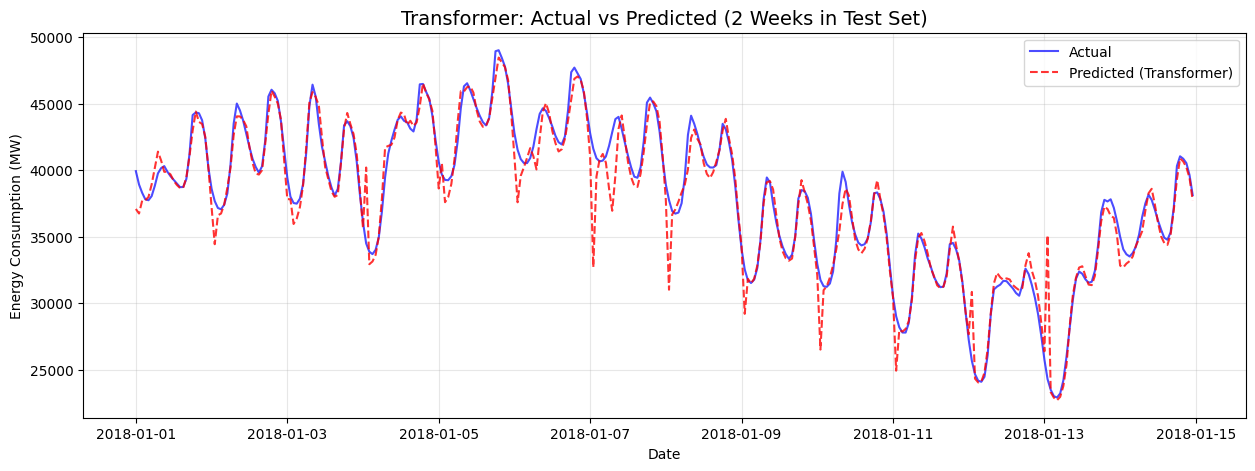

In [23]:
# ==========================================
# 3. Plotting (Actual vs Predicted)
# ==========================================
test_dates_tf = test.index[WINDOW_SIZE:] 

test_results_tf = pd.DataFrame({
    'Actual': y_test_mw.flatten(),
    'Predicted': y_pred_mw_tf.flatten()
}, index=test_dates_tf)

# Sort and remove duplicates to prevent KeyError
test_results_tf = test_results_tf.sort_index()
test_results_tf = test_results_tf[~test_results_tf.index.duplicated(keep='first')]

# Zoom in on 2 weeks
mask_tf = (test_results_tf.index >= '2018-01-01') & (test_results_tf.index < '2018-01-15')
zoom_tf = test_results_tf[mask_tf]

plt.figure(figsize=(15, 5))
plt.plot(zoom_tf.index, zoom_tf['Actual'], label='Actual', color='blue', alpha=0.7)
plt.plot(zoom_tf.index, zoom_tf['Predicted'], label='Predicted (Transformer)', color='red', linestyle='--', alpha=0.8)
plt.title('Transformer: Actual vs Predicted (2 Weeks in Test Set)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 📈 Visual Evaluation: Transformer vs. Actual

The plot compares the actual energy consumption (blue) with the Transformer's predictions (red dashed line) over a two-week period.

*   **Strong Pattern Tracking:** The Transformer successfully captures the complex daily cycles and weekly trends, closely following the actual load variations.
*   **Midnight Artifacts:** Similar to the LSTM, there are brief, sudden downward spikes in predictions exactly at midnight (e.g., Jan 7, Jan 9, Jan 13). This occurs because the 24-hour sliding window resets the cyclic time features at the start of a new day, momentarily disrupting the model's context. However, the model immediately self-corrects in the next hour.
*   **Conclusion:** Visually, the Transformer proves to be a highly capable model, performing significantly better than XGBoost and matching the LSTM's ability to forecast short-term energy demand.

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> ⚖️ Model Comparison </p>

In [38]:
# Combine the metrics into a single dictionary
all_metrics = {
    'XGBoost (No lag_1)': xgb_metrics,
    'LSTM (Sequence)': lstm_metrics,
    'Transformer (Sequence)': transformer_metrics
}

# Create a pandas DataFrame
comparison_df = pd.DataFrame(all_metrics).T

# Rename columns for better readability
comparison_df.columns = ['RMSE (MW)', 'MAE (MW)', 'MAPE (%)']

# Round the numbers to 2 decimal places
comparison_df = comparison_df.round(2)

# Display the table
print("--- Final Model Comparison on Test Set ---")
display(comparison_df)

--- Final Model Comparison on Test Set ---


,RMSE (MW),MAE (MW),MAPE (%)
XGBoost (No lag_1),1363.82,1012.36,3.21
LSTM (Sequence),723.58,372.89,1.26
Transformer (Sequence),735.86,413.68,1.37


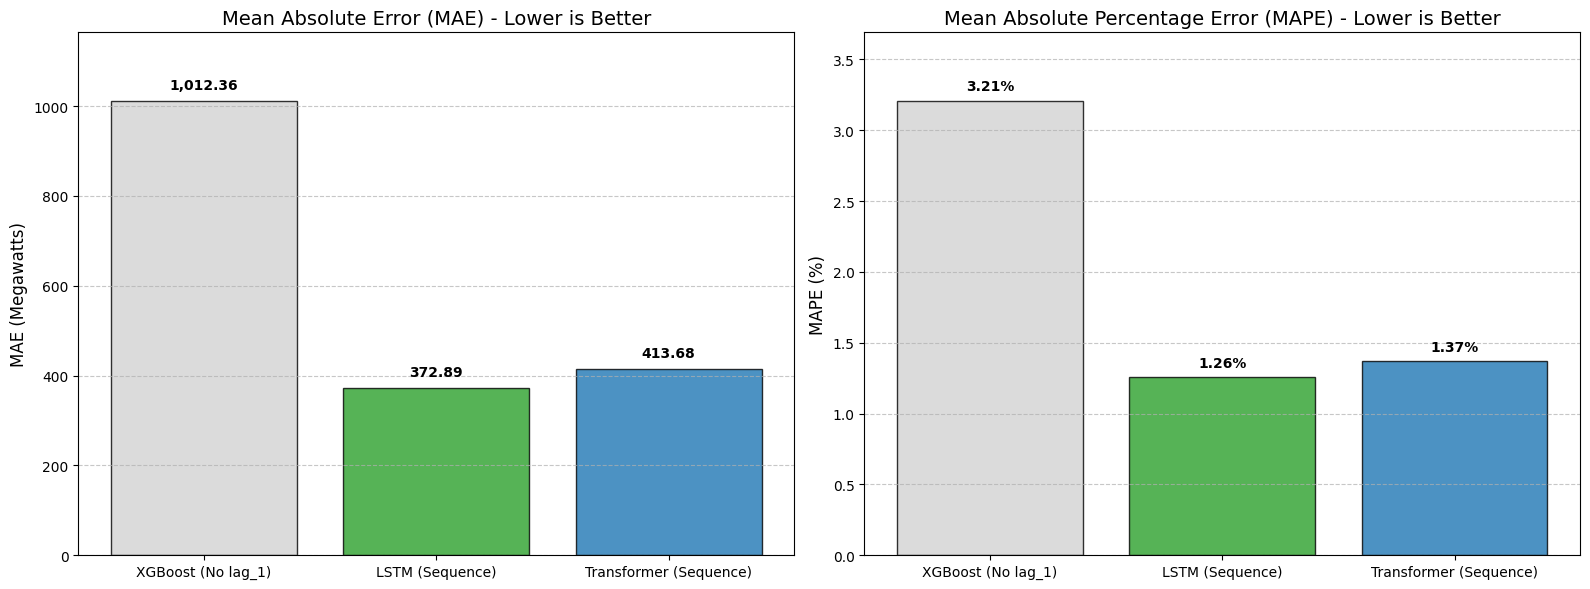

In [39]:
# Data preparation
models = comparison_df.index
mae_values = comparison_df['MAE (MW)']
mape_values = comparison_df['MAPE (%)']

# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: MAE (Megawatts) ---
colors_mae = ['#D3D3D3', '#2ca02c', '#1f77b4'] # Gray for XGB, Green for LSTM, Blue for Transformer
bars1 = axes[0].bar(models, mae_values, color=colors_mae, edgecolor='black', alpha=0.8)
axes[0].set_title('Mean Absolute Error (MAE) - Lower is Better', fontsize=14)
axes[0].set_ylabel('MAE (Megawatts)', fontsize=12)
axes[0].set_ylim(0, max(mae_values) * 1.15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of bars
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 20, f'{yval:,.2f}', ha='center', va='bottom', fontweight='bold')

# --- Chart 2: MAPE (Percentage) ---
colors_mape = ['#D3D3D3', '#2ca02c', '#1f77b4'] 
bars2 = axes[1].bar(models, mape_values, color=colors_mape, edgecolor='black', alpha=0.8)
axes[1].set_title('Mean Absolute Percentage Error (MAPE) - Lower is Better', fontsize=14)
axes[1].set_ylabel('MAPE (%)', fontsize=12)
axes[1].set_ylim(0, max(mape_values) * 1.15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of bars
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### ⚖️ Final Model Comparison

The table and the bar charts above summarize the final performance of all three models on the unseen Test Set (2017–2018). The results reveal several critical insights:

*   **Deep Learning Dominance:** Both Deep Learning models (LSTM and Transformer) drastically outperformed the XGBoost baseline. By processing the data as a continuous 24-hour sequence, they captured the temporal momentum of energy consumption. This reduced the relative error (MAPE) from **3.21% down to ~1.3%**, and the absolute error (MAE) by nearly **60%**.
*   **The Winner: LSTM (Sequence):** The LSTM model achieved the best overall performance with a **MAPE of 1.26%** and an **MAE of 372.89 MW**. Its recurrent architecture is inherently designed to remember short-term dependencies, naturally prioritizing the most recent hours in the sequence.
*   **The Runner-Up: Transformer (Sequence):** The Transformer performed exceptionally well (**MAPE of 1.37%**) but slightly lagged behind the LSTM. While Transformers excel at capturing long-range global dependencies, our context window is only 24 hours. For short-term, 1-hour-ahead forecasting, the LSTM's natural focus on the immediate past gives it a slight structural edge.
*   **The Baseline Limitation:** XGBoost (MAPE 3.21%) struggled without the `lag_1` feature. Tree-based models treat each row independently and lack the sequential memory required to track the smooth, continuous curves of energy load.

**Conclusion:** This experiment proves that for short-term time-series forecasting, maintaining the chronological sequence of data is vital. While advanced attention mechanisms are powerful, a well-tuned LSTM remains a highly competitive (and slightly superior) choice for this specific 1-hour-ahead task.

# <p style="padding:10px;background:linear-gradient(90deg,#BF360C 0%,#E64A19 100%);margin:0;color:white;font-family:newtimeroman;font-size:150%;text-align:center;border-radius:15px;overflow:hidden;font-weight:500"> 🎯 Conclusion & Future Work </p>

## 🎯 Conclusion

In this project, we evaluated three approaches for 1-hour-ahead energy forecasting: XGBoost (tree-based), LSTM, and Transformer (deep learning). 

**Key Findings:**
*   **The Power of Sequences:** By removing the 1-hour lag (`lag_1`) to prevent "cheating," XGBoost struggled with short-term dynamics (**MAPE: 3.21%**). Deep Learning models, fed with 24-hour sequences, naturally captured temporal momentum and drastically outperformed the baseline (**MAPE: ~1.3%**).
*   **LSTM vs. Transformer:** **LSTM emerged as the winner (MAPE: 1.26%, MAE: 372 MW).** While the Transformer performed exceptionally well (**MAPE: 1.37%**), LSTMs have an inherent architectural advantage for short-term 1-hour forecasting, as their recurrent nature naturally prioritizes the most recent timesteps.

## 🚀 Future Work

To further improve accuracy, future iterations could:
*   **Incorporate Exogenous Variables:** Adding historical weather data (temperature/humidity) to account for extreme weather peaks.
*   **Multi-Step Forecasting:** Extending the horizon to predict the next 24 hours simultaneously using Sequence-to-Sequence (Seq2Seq) models.
*   **Ensemble Modeling:** Combining the strengths of XGBoost, LSTM, and Transformer into a unified predictive model.

<div style="background: linear-gradient(135deg, #1A1A1A, #2D2D2D); 
            padding:30px; border-radius:15px; 
            box-shadow:0px 10px 30px rgba(0,0,0,0.4); margin-top: 30px; text-align: center; border: 1px solid #BF360C;">

<h2 style="color:#E64A19; font-size:24px; margin-top:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">
⚡ Found This Notebook Helpful?
</h2>

<p style="color:#E0E0E0; font-size:16px; line-height:1.8; margin-bottom: 20px;">
If this project helped you understand Time-Series Forecasting, Feature Engineering, or Deep Learning comparison, please consider:
</p>

<div style="display: flex; justify-content: center; gap: 20px; flex-wrap: wrap; margin-bottom: 20px;">
    <div style="background-color: rgba(230, 74, 25, 0.1); padding: 10px 20px; border-radius: 8px; border: 1px solid #E64A19;">
        <span style="color: #E64A19; font-size: 20px;">⬆️</span>
        <span style="color: white; font-size: 16px; font-weight: bold; margin-left: 10px;">Upvoting</span>
    </div>
    <div style="background-color: rgba(230, 74, 25, 0.1); padding: 10px 20px; border-radius: 8px; border: 1px solid #E64A19;">
        <span style="color: #E64A19; font-size: 20px;">💬</span>
        <span style="color: white; font-size: 16px; font-weight: bold; margin-left: 10px;">Leaving Feedback</span>
    </div>
</div>

<p style="color:#B0BEC5; font-size: 14px; font-style: italic; margin: 0;">
Your feedback and comments are highly appreciated and help me improve future projects! <br>
Happy Forecasting! ⚡📊
</p>

</div>